# Cartera en un entorno recesivo

## Factor 1: La beta de mercado

Ante una entorno económico recesivo las empresas de menor $\beta$ deberían sufrir en promedio una caída menor que el índice.

**Exposición Propuesta:** 0.75 con una banda de 0.05.

## Factor 2: Calidad

Seleccionaremos empresas de mayor calidad es decir con mayor capacidad para mantener los beneficios, generar caja y financiarse cuando se deteriora el entorno macroeconómico.

Una empresas de calidad debería presentar:
- Rentabildiad operativa elevada y relativamente estable
- Endeudamiento financiero controlado
- Capacidad recurrente de generar flujos de caja
- Menor dependencia de la refinanciación
- Resistencia de sus márgenes ante disminuciones de demanda.

Vamos a definir un factor de calidad:
$$Calidad_i=z(ROIC_i)+z(FCF_i)-z(Apalancamiento_i)$$

Donde:

$ROIC$ es la rentabilidad sobre capital invertido.
$$ROIC=\frac{NOPAT}{CapitalInvertido}=\frac{EBIT(1-\tau)}{Patrimonio+Deuda-Caja}$$

Pero tendremos que utilizar el $ROA$

$$ROA=\frac{EBIT}{ActivoTotal}$$

**Aplancamiento** intentamos reflejar la capacidad de atender la deuda

$$Apalancamiento=\frac{DeudaFinanciera- Caja}{EBITDA}$$

$FCF$ es el flujo de caja libre que lo estimamos sobre capital invertido:

$$FCF=\frac{FCF}{CapitalInvertido}$$

**Exposición Propuesta:** +0.75.

## Factor 3: Value, exposición positiva pero moderada

Un indicador de *Value* puede ser por dos causas:
- Value por infravaloración: negocio sólido que cotiza a precios atractivos
- Value por dificultdades: el mercado esta anticipando dificultades financieras.

No siempre es fácil diferenciar las dos causas, por ello apostamos de manera moderada a este factor.

**Exposición propuesta:** +0.10

## Factor 4: Momentum: exposición positiva, pero pruedente

Un momentum positivo puede significar resiliencia en momentos de crisis, pero nos preocupa mucho los rebotes de las compañías que han caído.

**Exposición Propuesta:** +0.20.




In [ ]:
import numpy as np
import pandas as pd
import cvxpy as cp
import datetime as dt
import yfinance as yf
import missingno as mso


In [ ]:
filepath = 'https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python-2023/main/Tema_5_APT/data/sp500_tickers.csv'
tickers_sp500 = list(pd.read_csv(filepath))

start_date = '2014-12-01'
end_date = '2020-12-31'

stocks_list = tickers_sp500

precios = yf.download(
    tickers=stocks_list,
    start=start_date,
    end=end_date,
    interval="1mo",
    auto_adjust=True
)['Close']
precios.head()

precios_activos_sp500 = precios.copy()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
32 Failed downloads:
ERROR:yfinance:['PEAK', 'MRO', 'CDAY', 'CTLT', 'BF.B', 'HES', 'BRK.B', 'WBA', 'ANSS', 'JNPR', 'FLT', 'MMC', 'WRK', 'DFS', 'PXD', 'HOLX']: YFTzMissingError('possibly delisted; no timezone found')
ERROR:yfinance:['CTRA', 'CEG', 'CMA', 'KVUE', 'FI', 'PARA', 'VLTO', 'K', 'AVB', 'GEHC', 'EA', 'BK', 'QRVO', 'WBD', 'IPG', 'EQR']: YFPricesMissingError('possibly delisted; no price data found  (1mo 2014-12-01 -> 2020-12-31) (Yahoo error = "Data doesn\'t exist for startDate = 1417410000, endDate = 1609390800")')


<Axes: >

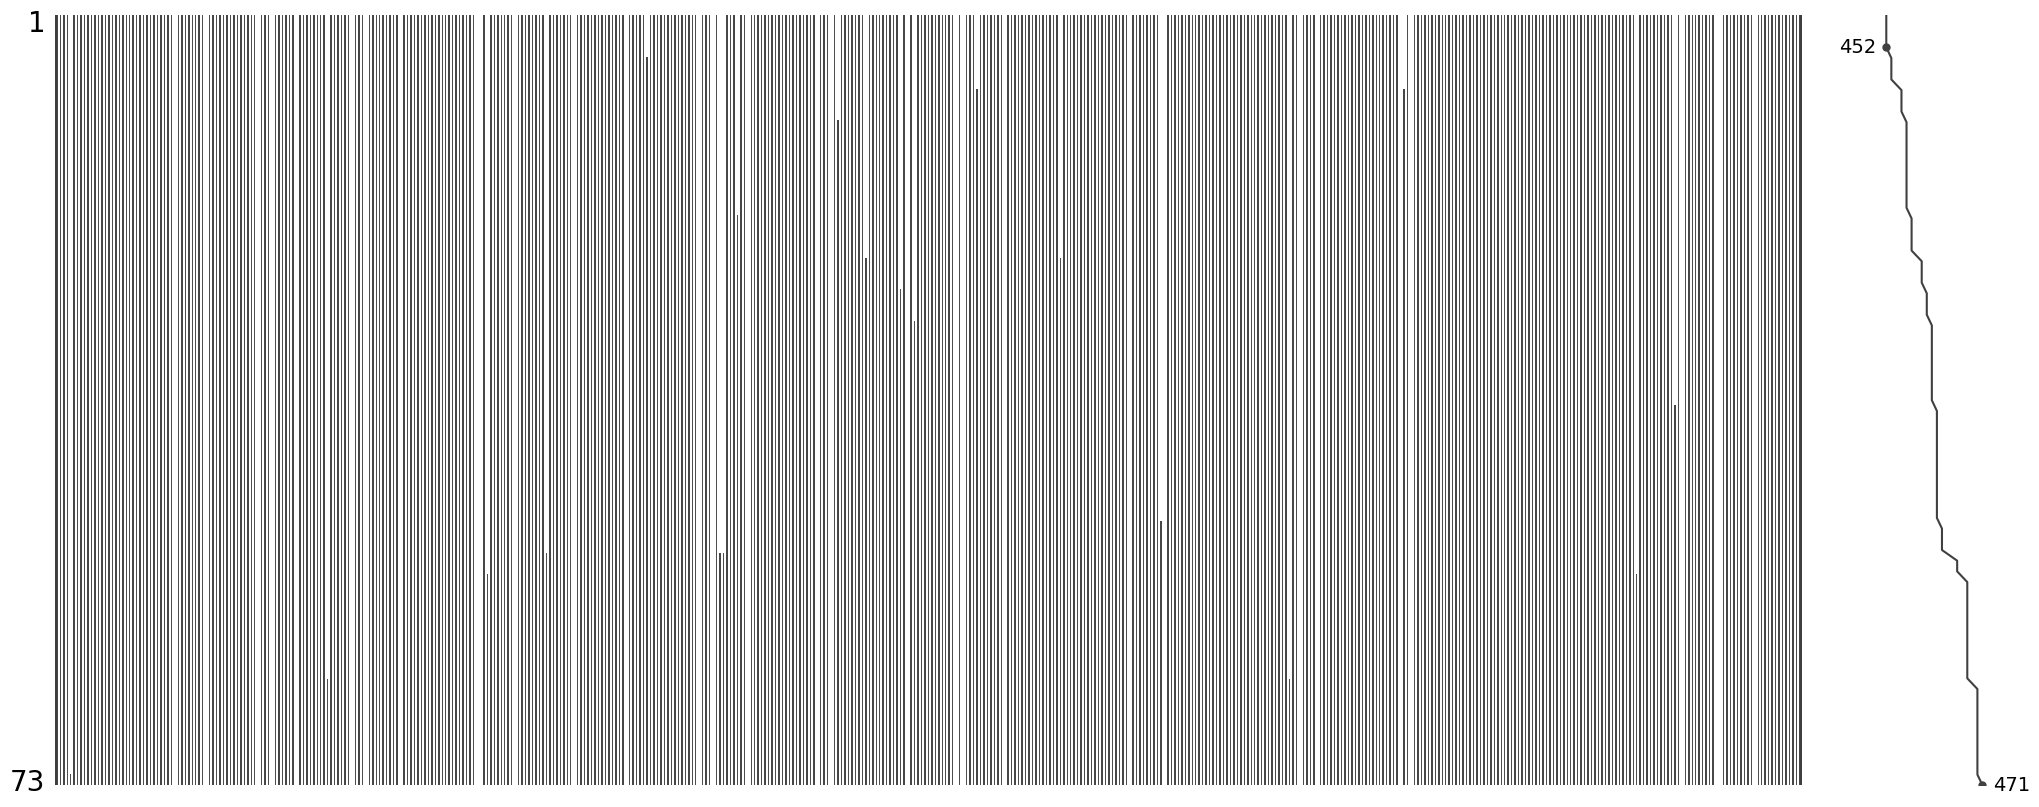

In [ ]:
import missingno as mso

mso.matrix(precios_activos_sp500)

Número de activos originales: 503
Número de activos con 73 datos completos: 452


<Axes: >

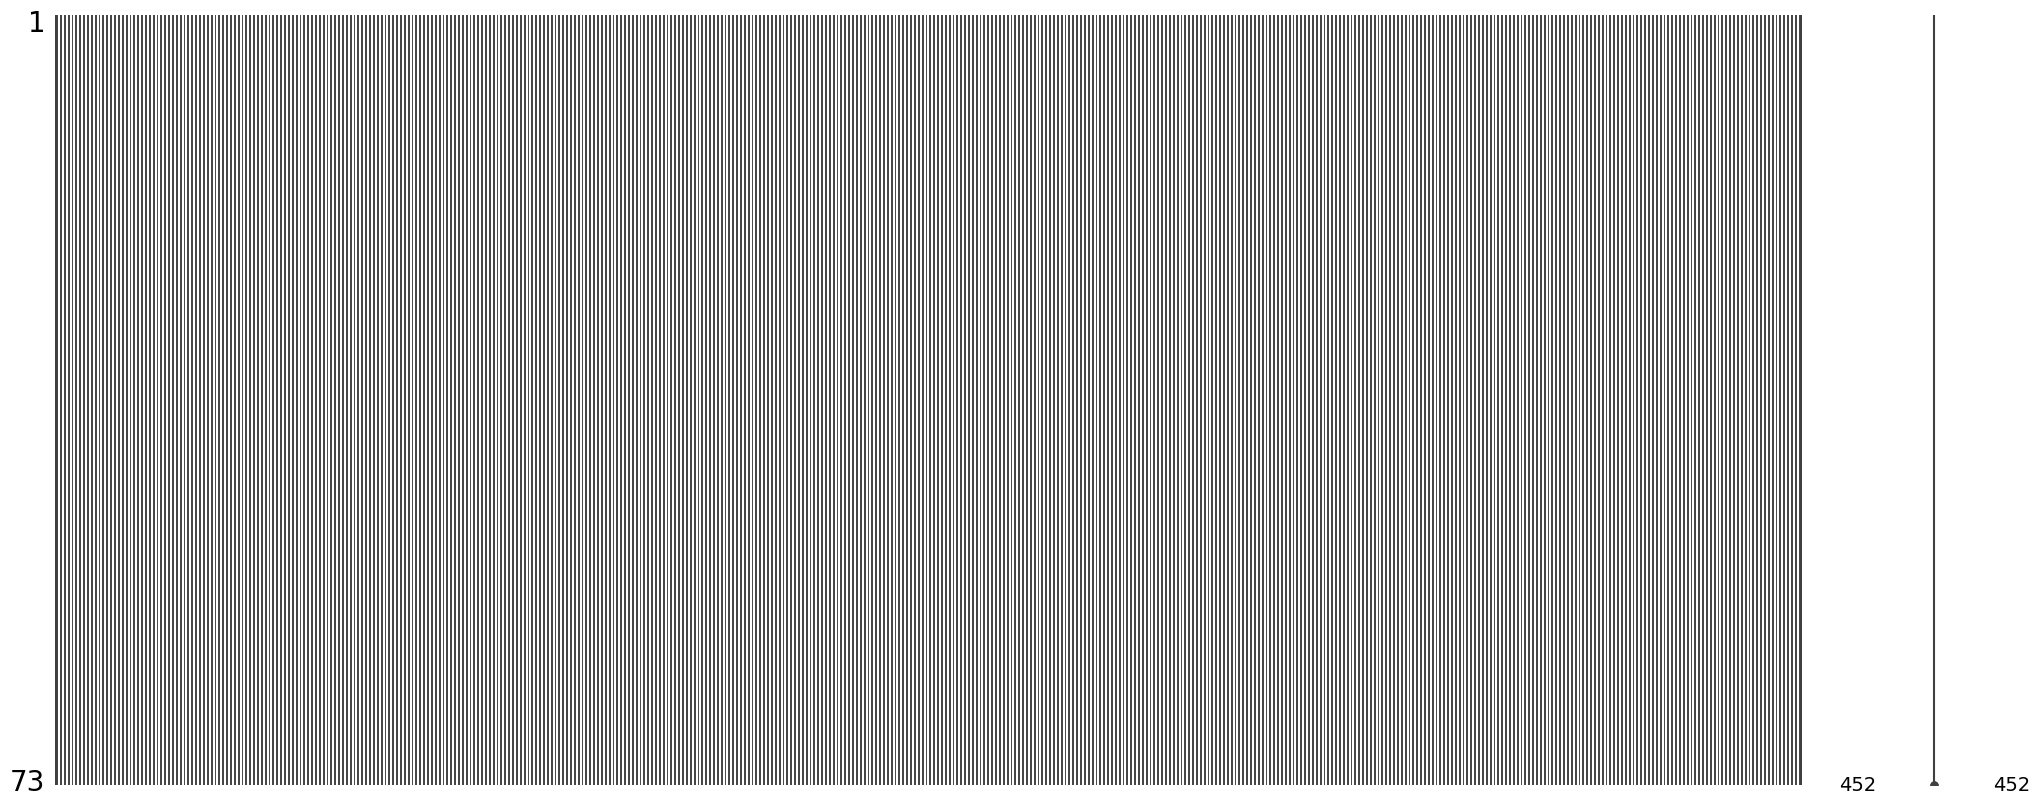

In [ ]:
# Filtramos para quedarnos solo con las columnas que tienen los 73 datos completos (sin NaNs)
precios_completos = precios_activos_sp500.dropna(axis=1, thresh=73)

print(f"Número de activos originales: {precios_activos_sp500.shape[1]}")
print(f"Número de activos con 73 datos completos: {precios_completos.shape[1]}")

# Visualizamos la matriz para confirmar que no quedan datos faltantes
mso.matrix(precios_completos)

In [ ]:
# Rentabilidades logarítmicas
rets = np.log(precios_completos / precios_completos.shift(1))


In [ ]:
# Periodo de estimación
rets_est= rets.loc["2015-01":"2019-12"].copy()

# Periodo fuera de muestra
rets_test = rets.loc["2020-01":"2020-12"].copy()

print("Estimación:", rets_est.shape)
print("Evaluación:", rets_test.shape)


Estimación: (60, 452)
Evaluación: (12, 452)


In [ ]:
rets_est.head()

Ticker,A,AAL,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WYNN,XEL,XOM,XRAY,XYL,YUM,ZBH,ZBRA,ZION,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-01,-0.078147,-0.088657,0.059611,-0.073494,-0.000513,-0.019305,-0.060940,-0.035991,-0.063387,-0.109000,...,-0.005460,0.043846,-0.055944,-0.062751,-0.110129,-0.002192,-0.011707,0.075251,-0.173869,-0.005118
2015-02-01,0.111142,-0.022312,0.096016,0.002482,0.056675,0.020320,0.068969,0.120362,0.123086,0.032439,...,-0.027785,-0.061824,0.020230,0.057858,0.049821,0.115259,0.071345,0.087041,0.111296,0.075695
2015-03-01,-0.013299,0.097017,-0.031874,-0.032933,-0.022200,0.040416,0.039849,-0.067459,0.073424,-0.010076,...,-0.124013,-0.004079,-0.040803,-0.039423,-0.019232,-0.029909,-0.022282,-0.003631,0.009676,0.004330
2015-04-01,-0.004342,-0.086860,0.005770,0.107692,0.007044,-0.015048,-0.000524,0.028268,-0.018584,0.030746,...,-0.125168,-0.026195,0.027500,0.002159,0.055540,0.093235,-0.067584,0.014880,0.048438,-0.039443
2015-05-01,-0.004361,-0.130784,0.044341,0.029412,0.045893,0.051549,0.035936,0.039064,0.100370,0.083373,...,-0.093707,0.004120,-0.016913,0.020187,-0.008411,0.047149,0.039925,0.174544,0.020934,0.113722


In [ ]:
indice = yf.download(
    tickers="^GSPC",
    start=start_date,
    end=end_date,
    interval="1mo",
    auto_adjust=True
)['Close']

indice.head()


[*********************100%***********************]  1 of 1 completed


Ticker,^GSPC
Date,
2014-12-01,2058.899902
2015-01-01,1994.989990
2015-02-01,2104.500000
2015-03-01,2067.889893
2015-04-01,2085.510010


In [ ]:
#Rentabilidad índice
SP500_ret = np.log(indice / indice.shift(1)).dropna()

# Periodo de estimación
SP500_ret_est = rets.loc["2015-01":"2019-12"].copy()

# Periodo fuera de muestra
SP500_ret_test = rets.loc["2020-01":"2020-12"].copy()

print("Estimación:", rets_est.shape)
print("Evaluación:", rets_test.shape)


Estimación: (60, 452)
Evaluación: (12, 452)


# Factor 1: La beta de mercado


In [ ]:
# Guarda la lista de tickers
assets = rets_test.columns

# Alinear ventanas
common = rets_est.index.intersection(SP500_ret_est.index) # identificamos las fechas comunes
rets_est_al = rets_est.loc[common] # seleccionamos las fechas comunes
SP500_ret_est_al = SP500_ret_est.loc[common]

def estimate_beta(asset_ret: pd.Series, mkt_ret: pd.Series, min_obs=24) -> float:
    df = pd.concat([asset_ret, mkt_ret], axis=1).dropna()
    if len(df) < min_obs:
        return np.nan
    x = df.iloc[:, 1].values
    y = df.iloc[:, 0].values
    x = x - x.mean()
    y = y - y.mean()
    return float((x @ y) / (x @ x))

beta = pd.Series({tkr: estimate_beta(rets_est_al[tkr], SP500_ret_est_al) for tkr in assets}, name="MktBeta")
beta.head()

,MktBeta
A,1.000000
AAL,0.601082
AAPL,0.422206
ABBV,0.528945
ABT,0.552785


##Factor 2: Calidad

## Factor Quality

In [ ]:
quality = pd.read_csv("quality.csv")

display(quality.head())
print(quality.columns.tolist())

,ticker,fecha_fiscal,ROA,FCF,activo_medio,FCF_Assets,Leverage,ROA_z,FCF_Assets_z,Leverage_z,Quality
0,A,2019-10-31,0.118934,866000000,9005000000,0.096169,0.497672,0.351268,-0.003640,0.574338,0.307322
1,AAPL,2019-09-28,0.156924,58896000000,352120500000,0.167261,0.732692,0.878225,1.005861,-0.509790,0.458098
2,ADBE,2018-11-30,0.155582,3762725000,16652119000,0.225961,0.501184,0.859619,1.839392,0.558139,1.085717
3,AEP,2018-12-31,0.028926,5208600000,66765950000,0.078013,0.721404,-0.897231,-0.261453,-0.457718,-0.538801
4,AKAM,2018-12-31,0.059021,790718000,5055343000,0.156412,0.415600,-0.479783,0.851812,0.952934,0.441654


['ticker', 'fecha_fiscal', 'ROA', 'FCF', 'activo_medio', 'FCF_Assets', 'Leverage', 'ROA_z', 'FCF_Assets_z', 'Leverage_z', 'Quality']


In [ ]:
quality = quality.set_index("ticker")

display(quality.head())

,fecha_fiscal,ROA,FCF,activo_medio,FCF_Assets,Leverage,ROA_z,FCF_Assets_z,Leverage_z,Quality
ticker,,,,,,,,,,
A,2019-10-31,0.118934,866000000,9005000000,0.096169,0.497672,0.351268,-0.003640,0.574338,0.307322
AAPL,2019-09-28,0.156924,58896000000,352120500000,0.167261,0.732692,0.878225,1.005861,-0.509790,0.458098
ADBE,2018-11-30,0.155582,3762725000,16652119000,0.225961,0.501184,0.859619,1.839392,0.558139,1.085717
AEP,2018-12-31,0.028926,5208600000,66765950000,0.078013,0.721404,-0.897231,-0.261453,-0.457718,-0.538801
AKAM,2018-12-31,0.059021,790718000,5055343000,0.156412,0.415600,-0.479783,0.851812,0.952934,0.441654


In [ ]:
quality = quality[["Quality"]]

# Alinear con las empresas de la cartera
quality = quality.reindex(assets)

quality.head()

,Quality
Ticker,
A,0.307322
AAL,NaN
AAPL,0.458098
ABBV,NaN
ABT,NaN


## Momentum

In [ ]:
#Estimamos el factor Momentum

mom_12_2 = (1 + SP500_ret_est).shift(2).rolling(11).apply(np.prod, raw=True) - 1
mom_signal = mom_12_2.iloc[-1]
mom_signal

,2019-12-01
Ticker,
A,0.019575
AAL,-0.322407
AAPL,0.350240
ABBV,-0.130632
ABT,0.137065
...,...
YUM,0.101510
ZBH,0.155209
ZBRA,0.227723


In [ ]:
# Estandarizar
mom_signal_z = (
    (mom_signal - mom_signal.mean())
    / mom_signal.std(ddof=0)
)


mom_signal_z.head()

,2019-12-01
Ticker,
A,-0.386183
AAL,-1.872448
AAPL,1.050891
ABBV,-1.038987
ABT,0.124430


## Señal Value

In [ ]:
value_signal = pd.read_csv("Book-to-Price.csv")

value_signal.head()


,ticker,fecha_equity,fecha_shares,BookEquity,Shares,Precio_2019,BookValue_per_Share,MarketCap,Book-to-Price,estado
0,A,2019-10-31,2019-07-31,4.748000e+09,3.100000e+08,85.309998,15.316129,2.644610e+10,0.179535,ok
1,AAL,2019-09-30,2019-09-30,1.600000e+08,4.380353e+08,28.680000,0.365267,1.256285e+10,0.012736,ok
2,AAPL,2019-09-28,2019-09-28,9.048800e+10,4.443236e+09,293.649994,20.365337,1.304756e+12,0.069352,ok
3,ABBV,2019-09-30,2019-10-29,-8.226000e+09,1.478821e+09,88.540001,-5.562539,1.309348e+11,NaN,Patrimonio neto no positivo
4,ABT,2019-09-30,2019-09-30,3.181700e+10,1.768456e+09,86.860001,17.991403,1.536081e+11,0.207131,ok


In [ ]:
value_signal= value_signal.set_index("ticker")

value_signal.head()

,fecha_equity,fecha_shares,BookEquity,Shares,Precio_2019,BookValue_per_Share,MarketCap,Book-to-Price,estado
ticker,,,,,,,,,
A,2019-10-31,2019-07-31,4.748000e+09,3.100000e+08,85.309998,15.316129,2.644610e+10,0.179535,ok
AAL,2019-09-30,2019-09-30,1.600000e+08,4.380353e+08,28.680000,0.365267,1.256285e+10,0.012736,ok
AAPL,2019-09-28,2019-09-28,9.048800e+10,4.443236e+09,293.649994,20.365337,1.304756e+12,0.069352,ok
ABBV,2019-09-30,2019-10-29,-8.226000e+09,1.478821e+09,88.540001,-5.562539,1.309348e+11,NaN,Patrimonio neto no positivo
ABT,2019-09-30,2019-09-30,3.181700e+10,1.768456e+09,86.860001,17.991403,1.536081e+11,0.207131,ok


In [ ]:
value_signal = value_signal[["Book-to-Price"]]

value_signal.head()

,Book-to-Price
ticker,
A,0.179535
AAL,0.012736
AAPL,0.069352
ABBV,NaN
ABT,0.207131


In [ ]:
# Alinear con las empresas de la cartera
value_signal = value_signal.reindex(assets)

# Estandarizar
value_z = (
    (value_signal - value_signal.mean())
    / value_signal.std(ddof=0)
)


value_z.head()

,Book-to-Price
Ticker,
A,-0.055616
AAL,-0.055616
AAPL,-0.055616
ABBV,NaN
ABT,-0.055616


## Matrix X

In [ ]:
# Convertir cada factor a una Serie
def convertir_serie(datos, nombre): # datos: el df con el factor
    if isinstance(datos, pd.DataFrame): # verificamos que es un DataFrame
        if nombre in datos.columns:
            datos = datos[nombre] # selecciona la columna y la convierte en serie
        elif datos.shape[1] == 1: # si no coincide y tiene sólo una columna
            datos = datos.iloc[:, 0]
        else:
            raise ValueError(
                f"Indica qué columna corresponde a {nombre}"
            )

    return datos.rename(nombre)

beta_s = convertir_serie(beta, "MktBeta")
quality_s = convertir_serie(quality, "Quality")
mom_s = convertir_serie(mom_signal_z, "Mom")
value_s = convertir_serie(value_z, "Value")

# Unir por ticker
X = pd.concat(
    [value_s, mom_s, beta_s, quality_s],
    axis=1,
    join="inner" # conseva únicamente los índices que están ent todos los objetos combinados
)

# Eliminar valores ausentes o infinitos
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

display(X.head())


,Value,Mom,MktBeta,Quality
A,-0.055616,-0.386183,1.000000,0.307322
AAPL,-0.055616,1.050891,0.422206,0.458098
ADBE,-0.055616,-0.107428,0.497063,1.085717
AEP,-0.055615,0.559050,0.114073,-0.538801
AKAM,-0.055616,0.501326,0.034964,0.441654


In [ ]:

print("Activos con Value:", value_s.notna().sum())
print("Activos con Momentum:", mom_s.notna().sum())
print("Activos con Beta:", beta_s.notna().sum())
print("Activos con Quality:", quality_s.notna().sum())

print("\nActivos con los cuatro factores:", len(X))
print("Valores ausentes en X:", X.isna().sum().sum()) # sumamos columnas y luego el total

print("\nDimensiones de X:", X.shape)
display(X.describe().T)


Activos con Value: 361
Activos con Momentum: 452
Activos con Beta: 452
Activos con Quality: 184

Activos con los cuatro factores: 161
Valores ausentes en X: 0

Dimensiones de X: (161, 4)


,count,mean,std,min,25%,50%,75%,max
Value,161.0,-0.055050,0.006762,-0.055616,-0.055616,-0.055616,-0.055615,0.030078
Mom,161.0,-0.058275,0.911945,-2.350002,-0.675288,-0.010160,0.530295,2.256447
MktBeta,161.0,0.459553,0.214359,-0.017801,0.300172,0.454157,0.579294,1.081885
Quality,161.0,0.022952,0.723219,-1.565081,-0.421207,-0.114406,0.371929,2.733697


In [ ]:
# Rentabilidades de los mismos activos
R_final = rets_est.reindex(columns=X.index)



In [ ]:
# Covarianza mensual por pares de activos
Sigma = R_final.cov(min_periods=45)

print("Dimensiones de Sigma:", Sigma.shape)


Sigma.iloc[:5, :5]


Dimensiones de Sigma: (161, 161)


,A,AAPL,ADBE,AEP,AKAM
A,0.004207,0.001776,0.002091,0.000480,0.000147
AAPL,0.001776,0.005794,0.002513,0.000375,0.001189
ADBE,0.002091,0.002513,0.003258,0.000115,0.000765
AEP,0.000480,0.000375,0.000115,0.001656,-0.000294
AKAM,0.000147,0.001189,0.000765,-0.000294,0.007286


## Identificamos la cartera


In [ ]:
def topdown_cvxpy(
    X: pd.DataFrame,
    Sigma: np.ndarray,
    targets: pd.Series,
    w_prev: pd.Series | None = None,
    max_weight: float = 1,
    risk_aversion: float = 1.0,
    turnover_weight: float = 0.0,
    exp_weights: pd.Series | None = None,
    solver: str = "OSQP",
    beta_vec: pd.Series | None = None,
    beta_target: float | None = None,
    beta_band: float | None = None,   # si quieres banda en lugar de igualdad exacta
) -> pd.Series:

    assets = X.index
    N = len(assets)

    cols = targets.index.intersection(X.columns)
    if len(cols) == 0:
        raise ValueError("Targets no coincide con columnas de X.")

    B = X[cols].values
    b = targets.loc[cols].values

    a = np.ones(len(cols)) if exp_weights is None else exp_weights.reindex(cols).fillna(1.0).values
    w_prev_vec = np.zeros(N) if w_prev is None else w_prev.reindex(assets).fillna(0.0).values

    w = cp.Variable(N)

    exp_err  = B.T @ w - b
    exp_loss = cp.sum(cp.multiply(a, cp.square(exp_err)))
    risk_loss = cp.quad_form(w, Sigma)
    turn_loss = cp.sum_squares(w - w_prev_vec)

    cons = [cp.sum(w) == 1.0, w >= 0.0, w <= max_weight]

    # --- Neutralidad a mercado: beta' w = beta_target (o en banda)
    if beta_vec is not None and beta_target is not None:
        beta_aligned = beta_vec.reindex(assets).astype(float).values # garantiza que coincidan los ticker de las betas y de los activos
        if beta_band is None:
            cons.append(beta_aligned @ w == beta_target)
        else:
            cons += [
                beta_aligned @ w >= beta_target - beta_band,
                beta_aligned @ w <= beta_target + beta_band
            ]

    obj = cp.Minimize(exp_loss + risk_aversion*risk_loss + turnover_weight*turn_loss)
    prob = cp.Problem(obj, cons)
    prob.solve(solver=solver, verbose=False)

    if w.value is None:
        raise RuntimeError(f"Optimización fallida. Status={prob.status}")

    return pd.Series(np.array(w.value).ravel(), index=assets, name="weight")


In [ ]:
targets = pd.Series({
    "Value": 0.10,
    "Mom": 0.20,
    "Quality": 0.75
})

beta_vec = X["MktBeta"]
beta_target = 0.75
beta_band = 0.05

In [ ]:
w_opt = topdown_cvxpy(
    X=X,
    Sigma=Sigma,
    targets=targets,
    max_weight=0.10,
    risk_aversion=1.0,
    turnover_weight=0.0,
    beta_vec=beta_vec,
    beta_target=0.75,
    beta_band=0.05
)

print("Suma de pesos:", w_opt.sum())
print("Número de activos invertidos:",
      (w_opt > 1e-5).sum())

display(
    w_opt[w_opt > 1e-5]
    .sort_values(ascending=False)
)


Suma de pesos: 0.9999999999999996
Número de activos invertidos: 19


,weight
A,0.100000
AMCR,0.100000
ISRG,0.100000
VRTX,0.100000
MTD,0.100000
AMAT,0.091014
KLAC,0.089711
INTU,0.068431
RVTY,0.047294
DLTR,0.041216


In [ ]:
exposiciones = X.T @ w_opt

comparacion = pd.DataFrame({
    "Obtenida": exposiciones,
})

comparacion["Objetivo"] = pd.Series({
    "Value": 0.10,
    "Mom": 0.20,
    "MktBeta": 0.75,
    "Quality": 0.75
})

comparacion["Desviacion"] = (
    comparacion["Obtenida"] - comparacion["Objetivo"]
)

display(comparacion)

,Obtenida,Objetivo,Desviacion
Value,-0.047047,0.10,-0.147047
Mom,0.199778,0.20,-0.000222
MktBeta,0.700000,0.75,-0.050000
Quality,0.749898,0.75,-0.000102


## Cartera equiponderada

In [ ]:
# Universo común para las tres carteras
assets_finales = X.index
N = len(assets_finales)

# Cartera equiponderada
w_eq = pd.Series(
    1 / N,
    index=assets_finales,
    name="Equiponderada"
)

print("Número de activos:", N)
print("Suma de pesos:", w_eq.sum())

Número de activos: 161
Suma de pesos: 0.9999999999999998


## Cartera mínima varianza

In [ ]:
# Variable de decisión
w = cp.Variable(N)

# Objetivo: mínima varianza
objetivo = cp.Minimize(
    cp.quad_form(w, Sigma)
)

# Restricciones
restricciones = [
    cp.sum(w) == 1,
    w >= 0,
    w <= 0.10
]

# Optimización
problema = cp.Problem(objetivo, restricciones)
problema.solve(solver="OSQP")


# Guardar las ponderaciones de mínima varianza
w_mv = pd.Series(
    w.value.flatten(),# convertimos las solución en un vector
    index=assets_finales,
    name="Minima Varianza"
)

w_mv = w_mv / w_mv.sum()

print("Suma de pesos:", w_mv.sum())
print("Volatilidad anual estimada:",
      np.sqrt(w_mv.values @ Sigma @ w_mv.values) * np.sqrt(12))

display(w_mv.sort_values(ascending=False).head(20))


Suma de pesos: 1.0
Volatilidad anual estimada: 0.06748250383330558


,Minima Varianza
AEP,0.100000
CHD,0.100000
D,0.100000
SO,0.096274
CI,0.084340
RMD,0.082758
COP,0.068953
DRI,0.068857
AKAM,0.048178
BR,0.046656


## Evaluación fuera de la muestra

In [ ]:
# Alinear las ponderaciones
w_td = w_opt.reindex(assets_finales)

w_td = w_td / w_td.sum()

# Matriz de ponderaciones
W = pd.DataFrame({
    "Top-Down": w_td,
    "Minima Varianza": w_mv,
    "Equiponderada": w_eq
})

print("Suma de pesos por cartera:")
print(W.sum())

display(W.head())


Suma de pesos por cartera:
Top-Down           1.0
Minima Varianza    1.0
Equiponderada      1.0
dtype: float64


,Top-Down,Minima Varianza,Equiponderada
A,1.000000e-01,2.166686e-20,0.006211
AAPL,4.137865e-21,-1.819189e-20,0.006211
ADBE,3.793563e-20,-1.554122e-20,0.006211
AEP,-2.951695e-20,1.000000e-01,0.006211
AKAM,2.099140e-20,4.817758e-02,0.006211


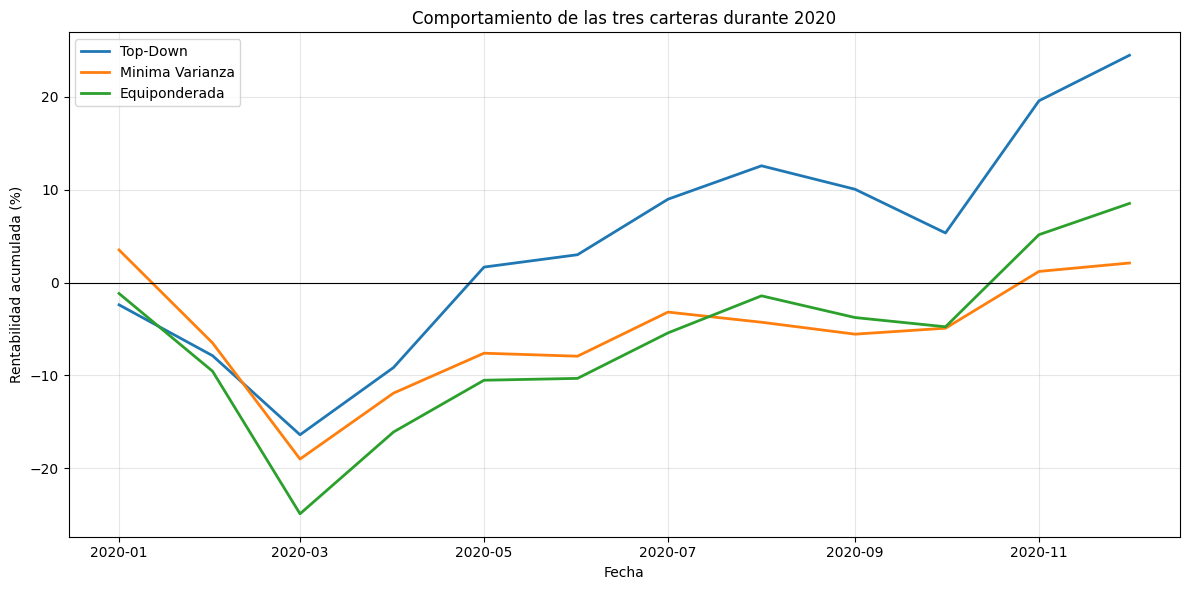

In [ ]:
import matplotlib.pyplot as plt

# Rentabilidades fuera de muestra
R_test = rets_test.loc[
    "2020-01":"2020-12"
].reindex(columns=assets_finales)


# Crecimiento de 1 dólar invertido en cada acción
crecimiento = (
    1 + R_test
).cumprod()

# Valor acumulado de las tres carteras
valor_carteras = crecimiento @ W

# Rentabilidad acumulada
rent_acum = valor_carteras - 1

# Gráfico
plt.figure(figsize=(12, 6))

for cartera in rent_acum.columns:
    plt.plot(
        rent_acum.index,
        rent_acum[cartera] * 100,
        linewidth=2,
        label=cartera
    )

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Comportamiento de las tres carteras durante 2020")
plt.ylabel("Rentabilidad acumulada (%)")
plt.xlabel("Fecha")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()